# ACA N.º 2 · Aprendizaje Automático (CUN)
## Paso 1. Exploración y gestión de datos con SQL
**Proyecto:** Predicción de deserción estudiantil con redes neuronales
**Pilar:** Educación · **Dataset:** UCI *Predict Students Dropout and Academic Success* (Martins et al., 2021)
**Docente:** Dr. Hamilton Rivera Flor

**Integrantes:** Johan Manuel Buitrago Segura · Yadlif Mateo Hernández Zapata · Cristian David Muñoz Sánchez · Edna Catalina Osorio Alzate · Camilo José Patiño Rodríguez

---
### ¿Qué hace este notebook?
El enunciado pide gestionar el dataset *«mediante una base de datos SQL (como SQLite, DuckDB u otra) para el almacenamiento, inserción y consulta eficiente de datos»*. Este notebook:

1. **Diseña** una base de datos relacional en **SQLite** con tres tablas relacionadas.
2. **Almacena** los 4.424 registros del dataset limpio de la ACA 1.
3. **Demuestra la inserción** de un registro nuevo dentro de una transacción.
4. **Optimiza** las consultas con índices.
5. **Explora** los datos con consultas SQL (EDA con `JOIN`, `GROUP BY`, `CASE` y CTE).
6. **Entrega** una vista lista para el modelo neuronal: el Paso 2 lee los datos **desde la base de datos**, no desde el CSV.

**¿Por qué SQLite?** Viene incluido en Python (no requiere instalar ni configurar un servidor), guarda toda la base en un solo archivo (`desercion.db`) que se puede subir a GitHub y compartir, y usa SQL estándar.

## 1. Librerías y carga del dataset
Se parte del dataset limpio de la ACA 1 (sin nulos ni duplicados, nombres de columnas en `snake_case`), que está en el repositorio del grupo.

In [1]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 50)
AZUL, NEGRO, GRIS = "#1d4ed8", "#0b1220", "#9aa6bf"

URL = ("https://raw.githubusercontent.com/Yadkomateo/Desercion_escolar_ACA1/"
       "main/artefactos/dataset_procesado.csv")
df = pd.read_csv(URL)
print("Filas y columnas:", df.shape)
print("Nulos totales:", int(df.isna().sum().sum()), "| Duplicados:", int(df.duplicated().sum()))
df.head(3)

Filas y columnas: (4424, 37)
Nulos totales: 0 | Duplicados: 0


,marital_status,application_mode,application_order,course,daytime_evening_attendance,previous_qualification,previous_qualification_grade,nationality,mothers_qualification,fathers_qualification,mothers_occupation,fathers_occupation,admission_grade,displaced,educational_special_needs,debtor,tuition_fees_up_to_date,gender,scholarship_holder,age_at_enrollment,international,curricular_units_1st_sem_credited,curricular_units_1st_sem_enrolled,curricular_units_1st_sem_evaluations,curricular_units_1st_sem_approved,curricular_units_1st_sem_grade,curricular_units_1st_sem_without_evaluations,curricular_units_2nd_sem_credited,curricular_units_2nd_sem_enrolled,curricular_units_2nd_sem_evaluations,curricular_units_2nd_sem_approved,curricular_units_2nd_sem_grade,curricular_units_2nd_sem_without_evaluations,unemployment_rate,inflation_rate,gdp,target
0,1,17,5,171,1,1,122.0,1,19,12,5,9,127.3,1,0,0,1,1,0,20,0,0,0,0,0,0.0,0,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,15,1,9254,1,1,160.0,1,1,3,3,3,142.5,1,0,0,0,1,0,19,0,0,6,6,6,14.0,0,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,9070,1,1,122.0,1,37,37,9,9,124.8,1,0,0,0,1,0,19,0,0,6,0,0,0.0,0,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout


## 2. Diseño de la base de datos (modelo relacional)
En lugar de guardar una sola tabla de 37 columnas, los datos se **normalizan** en tres tablas. Así se evita repetir información y el desempeño académico queda en formato *largo* (una fila por estudiante y semestre), que es la forma natural de guardar datos que se repiten en el tiempo.

| Tabla | Una fila por… | Contenido | Clave |
|---|---|---|---|
| `carreras` | carrera | código UCI y nombre de la carrera | `codigo` (PK) |
| `estudiantes` | estudiante | datos demográficos, socioeconómicos, de admisión, contexto macroeconómico y **resultado** (variable objetivo) | `estudiante_id` (PK), `course` → `carreras.codigo` (FK) |
| `desempeno_semestral` | estudiante y semestre | asignaturas convalidadas, inscritas, evaluadas, aprobadas, sin evaluar y promedio | (`estudiante_id`, `semestre`) (PK), `estudiante_id` → `estudiantes` (FK) |

```
carreras (1) ──< estudiantes (1) ──< desempeno_semestral (2 filas por estudiante)
```

In [2]:
conn = sqlite3.connect("desercion.db")
conn.execute("PRAGMA foreign_keys = ON")   # que SQLite haga cumplir las llaves foráneas
cur = conn.cursor()

cur.executescript("""
DROP TABLE IF EXISTS desempeno_semestral;
DROP TABLE IF EXISTS estudiantes;
DROP TABLE IF EXISTS carreras;

CREATE TABLE carreras (
    codigo  INTEGER PRIMARY KEY,
    nombre  TEXT NOT NULL
);

CREATE TABLE estudiantes (
    estudiante_id                  INTEGER PRIMARY KEY,
    marital_status                 INTEGER,
    application_mode               INTEGER,
    application_order              INTEGER,
    course                         INTEGER NOT NULL REFERENCES carreras(codigo),
    daytime_evening_attendance     INTEGER CHECK (daytime_evening_attendance IN (0, 1)),
    previous_qualification         INTEGER,
    previous_qualification_grade   REAL,
    nationality                    INTEGER,
    mothers_qualification          INTEGER,
    fathers_qualification          INTEGER,
    mothers_occupation             INTEGER,
    fathers_occupation             INTEGER,
    admission_grade                REAL,
    displaced                      INTEGER CHECK (displaced IN (0, 1)),
    educational_special_needs      INTEGER CHECK (educational_special_needs IN (0, 1)),
    debtor                         INTEGER CHECK (debtor IN (0, 1)),
    tuition_fees_up_to_date        INTEGER CHECK (tuition_fees_up_to_date IN (0, 1)),
    gender                         INTEGER CHECK (gender IN (0, 1)),
    scholarship_holder             INTEGER CHECK (scholarship_holder IN (0, 1)),
    age_at_enrollment              INTEGER CHECK (age_at_enrollment BETWEEN 15 AND 80),
    international                  INTEGER CHECK (international IN (0, 1)),
    unemployment_rate              REAL,
    inflation_rate                 REAL,
    gdp                            REAL,
    resultado                      TEXT NOT NULL CHECK (resultado IN ('Dropout', 'Enrolled', 'Graduate'))
);

CREATE TABLE desempeno_semestral (
    estudiante_id        INTEGER NOT NULL REFERENCES estudiantes(estudiante_id),
    semestre             INTEGER NOT NULL CHECK (semestre IN (1, 2)),
    convalidadas         INTEGER,
    inscritas            INTEGER,
    evaluadas            INTEGER,
    aprobadas            INTEGER,
    promedio             REAL CHECK (promedio BETWEEN 0 AND 20),
    sin_evaluaciones     INTEGER,
    PRIMARY KEY (estudiante_id, semestre)
);
""")
print("Tablas creadas:", [r[0] for r in cur.execute("SELECT name FROM sqlite_master WHERE type='table'")])

Tablas creadas: ['carreras', 'estudiantes', 'desempeno_semestral']


**Restricciones de integridad.** Además de las llaves, las tablas tienen reglas `CHECK`: las variables binarias solo aceptan 0 o 1, la edad debe estar entre 15 y 80, el promedio entre 0 y 20 y el resultado solo puede ser una de las tres clases. Si alguien intenta guardar un dato imposible, la base de datos lo rechaza. Es una capa de **calidad de datos** que actúa antes del modelo.

## 3. Almacenamiento: inserción masiva de los datos
Se separan las columnas del DataFrame según la tabla a la que pertenecen y se insertan con `to_sql`. El catálogo de carreras usa los nombres del diccionario de datos de la UCI.

In [3]:
CARRERAS = {
    33: "Tecnologías de producción de biocombustibles", 171: "Diseño de animación y multimedia",
    8014: "Servicio social (nocturno)", 9003: "Agronomía", 9070: "Diseño de comunicación",
    9085: "Enfermería veterinaria", 9119: "Ingeniería informática", 9130: "Equinocultura",
    9147: "Administración", 9238: "Servicio social", 9254: "Turismo", 9500: "Enfermería",
    9556: "Higiene oral", 9670: "Gestión de publicidad y marketing",
    9773: "Periodismo y comunicación", 9853: "Educación básica", 9991: "Administración (nocturno)",
}

# --- carreras
pd.DataFrame(list(CARRERAS.items()), columns=["codigo", "nombre"]) \
  .to_sql("carreras", conn, if_exists="append", index=False)

# --- estudiantes (una fila por estudiante)
datos = df.copy()
datos.insert(0, "estudiante_id", range(1, len(datos) + 1))
cols_sem = [c for c in datos.columns if c.startswith("curricular_units_")]
estudiantes = datos.drop(columns=cols_sem).rename(columns={"target": "resultado"})
estudiantes.to_sql("estudiantes", conn, if_exists="append", index=False)

# --- desempeño semestral (formato largo: dos filas por estudiante)
renombre = {"credited": "convalidadas", "enrolled": "inscritas", "evaluations": "evaluadas",
            "approved": "aprobadas", "grade": "promedio", "without_evaluations": "sin_evaluaciones"}
partes = []
for sem, etiqueta in [(1, "1st"), (2, "2nd")]:
    p = datos[["estudiante_id"] + [c for c in cols_sem if f"_{etiqueta}_sem_" in c]].copy()
    p.columns = ["estudiante_id"] + [renombre[c.split("_sem_")[1]] for c in p.columns[1:]]
    p.insert(1, "semestre", sem)
    partes.append(p)
pd.concat(partes).to_sql("desempeno_semestral", conn, if_exists="append", index=False)
conn.commit()

for t in ["carreras", "estudiantes", "desempeno_semestral"]:
    n = cur.execute(f"SELECT COUNT(*) FROM {t}").fetchone()[0]
    print(f"{t:<22} {n:>6,} filas".replace(",", "."))

carreras                   17 filas
estudiantes             4.424 filas
desempeno_semestral     8.848 filas


## 4. Consulta eficiente: índices
Un **índice** funciona como el índice de un libro: permite encontrar filas sin recorrer toda la tabla. Se crean sobre las columnas que más se usan para filtrar y agrupar. Con `EXPLAIN QUERY PLAN` se comprueba que SQLite efectivamente lo usa.

In [4]:
cur.executescript("""
CREATE INDEX IF NOT EXISTS idx_est_resultado ON estudiantes(resultado);
CREATE INDEX IF NOT EXISTS idx_est_carrera   ON estudiantes(course);
CREATE INDEX IF NOT EXISTS idx_sem_semestre  ON desempeno_semestral(semestre);
""")
plan = cur.execute("EXPLAIN QUERY PLAN SELECT COUNT(*) FROM estudiantes WHERE resultado = 'Dropout'").fetchall()
print("Plan de la consulta:", plan[0][-1])

Plan de la consulta: SEARCH estudiantes USING COVERING INDEX idx_est_resultado (resultado=?)


## 5. Inserción y control de calidad con transacciones
Se simula el registro de un estudiante nuevo dentro de una **transacción**: si cualquier dato viola una regla, nada queda guardado. Primero un registro válido (que luego se revierte para no alterar el dataset) y después uno inválido, que la base de datos rechaza.

In [5]:
def insertar_estudiante(conn, fila_est, filas_sem):
    """Inserta un estudiante y su desempeño en una sola transacción."""
    with conn:   # confirma si todo sale bien; revierte si algo falla
        cols = ", ".join(fila_est)
        conn.execute(f"INSERT INTO estudiantes ({cols}) VALUES ({', '.join('?' * len(fila_est))})",
                     list(fila_est.values()))
        conn.executemany("""INSERT INTO desempeno_semestral
            (estudiante_id, semestre, convalidadas, inscritas, evaluadas, aprobadas, promedio, sin_evaluaciones)
            VALUES (?, ?, ?, ?, ?, ?, ?, ?)""", filas_sem)

# Registro de prueba: se toma un estudiante real como plantilla y se le asigna un id nuevo
nuevo = pd.read_sql("SELECT * FROM estudiantes WHERE estudiante_id = 1", conn).iloc[0].to_dict()
nuevo = {k: (v.item() if hasattr(v, "item") else v) for k, v in nuevo.items()}
nuevo.update({"estudiante_id": 99999, "age_at_enrollment": 19, "resultado": "Enrolled"})
semestres = [(99999, 1, 0, 6, 6, 5, 13.2, 0), (99999, 2, 0, 6, 7, 6, 13.8, 0)]

# 5.1 Inserción válida
insertar_estudiante(conn, nuevo, semestres)
print("✅ Insertado:", pd.read_sql("SELECT estudiante_id, course, age_at_enrollment, resultado "
                                   "FROM estudiantes WHERE estudiante_id = 99999", conn).to_dict("records"))

# Se elimina el registro de prueba para no alterar el dataset original
with conn:
    conn.execute("DELETE FROM desempeno_semestral WHERE estudiante_id = 99999")
    conn.execute("DELETE FROM estudiantes WHERE estudiante_id = 99999")

# 5.2 Inserción inválida: resultado que no existe → la base de datos la rechaza
malo = dict(nuevo, estudiante_id=99998, resultado="Desconocido")
try:
    insertar_estudiante(conn, malo, [(99998, 1, 0, 6, 6, 5, 13.2, 0)])
except sqlite3.IntegrityError as e:
    print("⛔ Rechazado por la base de datos:", e)

print("Estudiantes en la base:", cur.execute("SELECT COUNT(*) FROM estudiantes").fetchone()[0])

✅ Insertado: [{'estudiante_id': 99999, 'course': 171, 'age_at_enrollment': 19, 'resultado': 'Enrolled'}]
⛔ Rechazado por la base de datos: CHECK constraint failed: resultado IN ('Dropout', 'Enrolled', 'Graduate')
Estudiantes en la base: 4424


## 6. Análisis exploratorio con SQL
Cada consulta responde una pregunta del problema. Se usa una función auxiliar para ejecutar SQL y recibir el resultado como tabla.

In [6]:
def sql(consulta):
    """Ejecuta una consulta SQL sobre la base y devuelve un DataFrame."""
    return pd.read_sql(consulta, conn)

### Consulta 1. ¿Cómo se distribuyen los resultados?

In [7]:
q1 = sql("""
SELECT resultado,
       COUNT(*)                                             AS estudiantes,
       ROUND(100.0 * COUNT(*) / (SELECT COUNT(*) FROM estudiantes), 1) AS porcentaje
FROM estudiantes
GROUP BY resultado
ORDER BY estudiantes DESC
""")
q1

,resultado,estudiantes,porcentaje
0,Graduate,2209,49.9
1,Dropout,1421,32.1
2,Enrolled,794,17.9


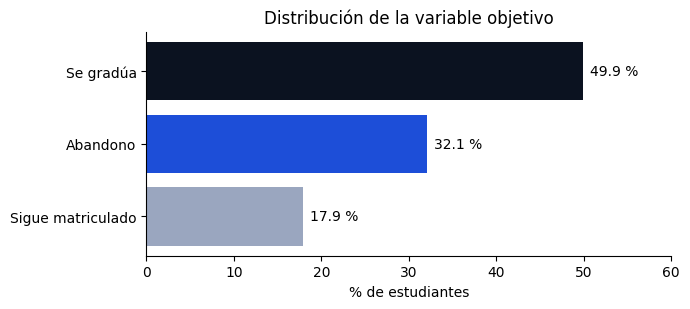

In [8]:
nombres = {"Graduate": "Se gradúa", "Dropout": "Abandono", "Enrolled": "Sigue matriculado"}
colores = {"Graduate": NEGRO, "Dropout": AZUL, "Enrolled": GRIS}
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.barh([nombres[r] for r in q1.resultado], q1.porcentaje, color=[colores[r] for r in q1.resultado])
for i, v in enumerate(q1.porcentaje):
    ax.text(v + 0.8, i, f"{v:.1f} %", va="center")
ax.invert_yaxis(); ax.set_xlabel("% de estudiantes"); ax.set_xlim(0, 60)
ax.set_title("Distribución de la variable objetivo"); ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

**Interpretación.** Casi la mitad de los estudiantes se gradúa (49,9 %), uno de cada tres abandona (32,1 %) y el 17,9 % sigue matriculado al cierre del periodo observado. Las clases están **desbalanceadas**, y eso tiene dos consecuencias para la red neuronal del Paso 3:
- Hay que compensar el desbalance durante el entrenamiento (pesos por clase o sobremuestreo solo en el conjunto de entrenamiento). Si no, la red tiende a predecir casi siempre «se gradúa».
- La exactitud (*accuracy*) sola engaña. La métrica principal sigue siendo el **F1 macro**, igual que en la ACA 1, para que las tres clases pesen lo mismo. La clase «sigue matriculado» es la más pequeña y la más difícil de predecir.

### Consulta 2. ¿En qué carreras se concentra la deserción? (`JOIN` con el catálogo)

In [9]:
q2 = sql("""
SELECT c.nombre                                                        AS carrera,
       COUNT(*)                                                        AS estudiantes,
       SUM(e.resultado = 'Dropout')                                    AS desertores,
       ROUND(100.0 * SUM(e.resultado = 'Dropout') / COUNT(*), 1)       AS tasa_desercion
FROM estudiantes e
JOIN carreras c ON c.codigo = e.course
GROUP BY c.nombre
HAVING COUNT(*) >= 50              -- se excluyen carreras con muy pocos estudiantes
ORDER BY tasa_desercion DESC
""")
q2

,carrera,estudiantes,desertores,tasa_desercion
0,Equinocultura,141,78,55.3
1,Ingeniería informática,170,92,54.1
2,Administración (nocturno),268,136,50.7
3,Educación básica,192,85,44.3
4,Agronomía,210,86,41.0
5,Higiene oral,86,33,38.4
6,Turismo,252,96,38.1
7,Diseño de animación y multimedia,215,82,38.1
8,Gestión de publicidad y marketing,268,95,35.4
9,Administración,380,134,35.3


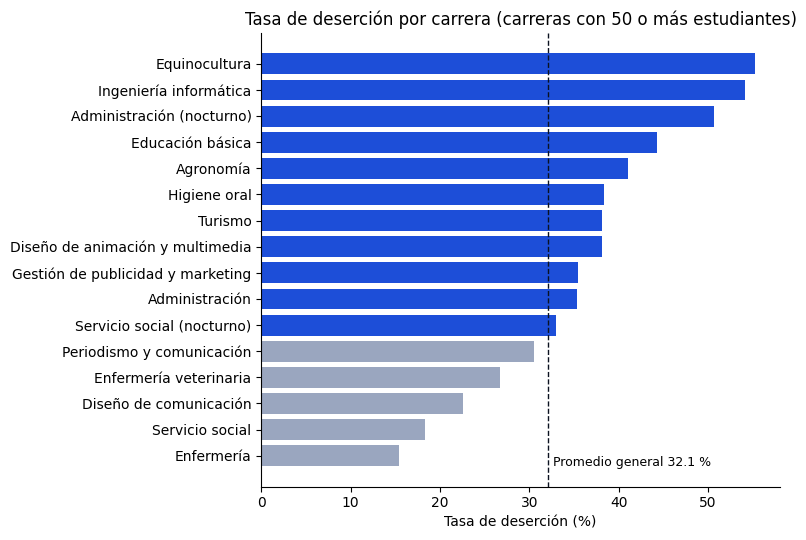

In [10]:
fig, ax = plt.subplots(figsize=(8, 5.5))
promedio = 100 * (df.target == "Dropout").mean()
col = [AZUL if t > promedio else GRIS for t in q2.tasa_desercion]
ax.barh(q2.carrera, q2.tasa_desercion, color=col)
ax.axvline(promedio, color=NEGRO, ls="--", lw=1)
ax.text(promedio + 0.5, len(q2) - 0.6, f"Promedio general {promedio:.1f} %", fontsize=9)
ax.invert_yaxis(); ax.set_xlabel("Tasa de deserción (%)")
ax.set_title("Tasa de deserción por carrera (carreras con 50 o más estudiantes)")
ax.spines[["top", "right"]].set_visible(False); plt.tight_layout(); plt.show()

**Interpretación.** La deserción varía mucho según la carrera: va de 15,4 % en Enfermería a 55,3 % en Equinocultura. Once de las 16 carreras analizadas superan el promedio general de 32,1 % (Tecnologías de biocombustibles se excluye porque solo tiene 12 estudiantes). Llama la atención Administración: la jornada nocturna tiene 50,7 % de deserción frente a 35,3 % en la diurna. Esto sugiere que las condiciones de los estudiantes nocturnos, que con frecuencia trabajan, pesan en la permanencia, aunque esta consulta por sí sola no prueba la causa.

**Implicación para el modelo:** la carrera es una variable **categórica**: su código (9500, 9119…) no tiene un orden numérico con significado. Por eso en el Paso 2 debe codificarse con *one-hot* y no entrar a la red como un número.

### Consulta 3. ¿Influye la situación financiera? (matrícula al día, deudas y beca)

In [11]:
q3 = sql("""
SELECT 'Matrícula al día'      AS factor, CASE tuition_fees_up_to_date WHEN 1 THEN 'Sí' ELSE 'No' END AS valor,
       COUNT(*) AS estudiantes, ROUND(100.0 * AVG(resultado = 'Dropout'), 1) AS tasa_desercion
FROM estudiantes GROUP BY tuition_fees_up_to_date
UNION ALL
SELECT 'Tiene deudas',     CASE debtor WHEN 1 THEN 'Sí' ELSE 'No' END,
       COUNT(*), ROUND(100.0 * AVG(resultado = 'Dropout'), 1)
FROM estudiantes GROUP BY debtor
UNION ALL
SELECT 'Tiene beca',       CASE scholarship_holder WHEN 1 THEN 'Sí' ELSE 'No' END,
       COUNT(*), ROUND(100.0 * AVG(resultado = 'Dropout'), 1)
FROM estudiantes GROUP BY scholarship_holder
""")
q3

,factor,valor,estudiantes,tasa_desercion
0,Matrícula al día,No,528,86.6
1,Matrícula al día,Sí,3896,24.7
2,Tiene deudas,No,3921,28.3
3,Tiene deudas,Sí,503,62.0
4,Tiene beca,No,3325,38.7
5,Tiene beca,Sí,1099,12.2


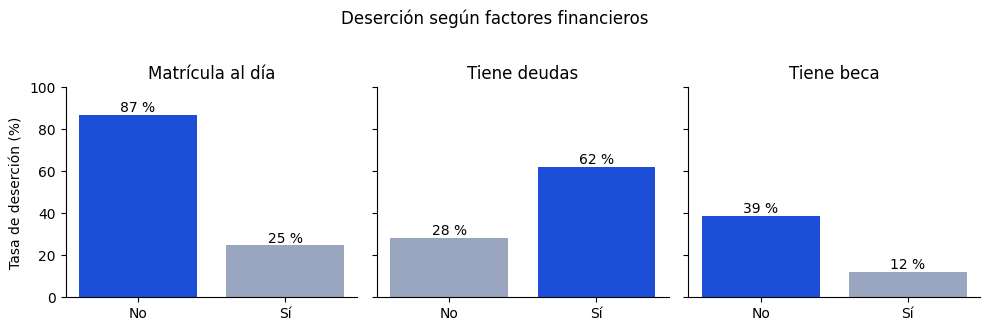

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(10, 3.2), sharey=True)
for ax, (factor, g) in zip(axes, q3.groupby("factor", sort=False)):
    g = g.sort_values("valor")
    ax.bar(g.valor, g.tasa_desercion,
           color=[AZUL if v == g.tasa_desercion.max() else GRIS for v in g.tasa_desercion])  # azul = mayor riesgo
    for i, v in enumerate(g.tasa_desercion):
        ax.text(i, v + 1.5, f"{v:.0f} %", ha="center")
    ax.set_title(factor); ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("Tasa de deserción (%)"); axes[0].set_ylim(0, 100)
plt.suptitle("Deserción según factores financieros", y=1.02); plt.tight_layout(); plt.show()

**Interpretación.** Los factores financieros muestran las diferencias más grandes del análisis:
- Quienes **no tienen la matrícula al día** abandonan en un 86,6 %, frente a 24,7 % de quienes sí están al día: 3,5 veces más.
- Quienes **tienen deudas** con la institución abandonan en un 62,0 %, frente a 28,3 %.
- Quienes **tienen beca** abandonan en un 12,2 %, frente a 38,7 % sin beca.

Esto coincide con la ACA 1, donde «matrícula al día» fue la tercera variable más influyente del modelo.

**Precaución metodológica:** la relación puede ir en ambos sentidos. Un estudiante que ya decidió irse deja de pagar, así que la matrícula atrasada puede ser tanto **causa** como **síntoma** del abandono. El modelo la aprovechará como señal de alerta, pero no debe leerse como prueba de que la falta de pago *causa* la deserción.

### Consulta 4. ¿Cómo cambia el desempeño académico entre semestres? (`JOIN` entre estudiantes y desempeño)

In [13]:
q4 = sql("""
SELECT e.resultado,
       d.semestre,
       ROUND(AVG(d.inscritas), 2)                                    AS inscritas,
       ROUND(AVG(d.aprobadas), 2)                                    AS aprobadas,
       ROUND(100.0 * SUM(d.aprobadas) / NULLIF(SUM(d.inscritas), 0), 1) AS tasa_aprobacion,
       ROUND(AVG(d.promedio), 2)                                     AS promedio_notas
FROM estudiantes e
JOIN desempeno_semestral d ON d.estudiante_id = e.estudiante_id
GROUP BY e.resultado, d.semestre
ORDER BY e.resultado, d.semestre
""")
q4

,resultado,semestre,inscritas,aprobadas,tasa_aprobacion,promedio_notas
0,Dropout,1,5.82,2.55,43.8,7.26
1,Dropout,2,5.78,1.94,33.6,5.90
2,Enrolled,1,5.96,4.32,72.4,11.13
3,Enrolled,2,5.94,4.06,68.3,11.12
4,Graduate,1,6.67,6.23,93.4,12.64
5,Graduate,2,6.63,6.18,93.2,12.70


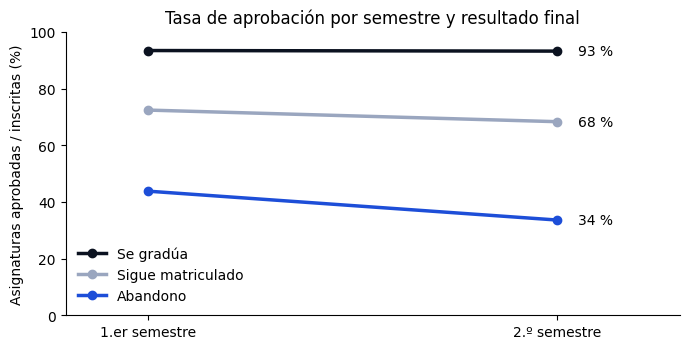

In [14]:
fig, ax = plt.subplots(figsize=(7, 3.6))
for r in ["Graduate", "Enrolled", "Dropout"]:
    g = q4[q4.resultado == r]
    ax.plot(g.semestre, g.tasa_aprobacion, marker="o", lw=2.5, color=colores[r], label=nombres[r])
    ax.text(2.05, g.tasa_aprobacion.iloc[-1], f"{g.tasa_aprobacion.iloc[-1]:.0f} %", va="center")
ax.set_xticks([1, 2], ["1.er semestre", "2.º semestre"]); ax.set_xlim(0.8, 2.3); ax.set_ylim(0, 100)
ax.set_ylabel("Asignaturas aprobadas / inscritas (%)"); ax.legend(frameon=False)
ax.set_title("Tasa de aprobación por semestre y resultado final")
ax.spines[["top", "right"]].set_visible(False); plt.tight_layout(); plt.show()

**Interpretación.** Los tres grupos inscriben una carga parecida (entre 5,8 y 6,7 asignaturas por semestre), así que la diferencia **no está en cuántas materias toman sino en cuántas aprueban**:
- Los que se gradúan aprueban el 93 % en ambos semestres, con un promedio de notas cercano a 12,7 sobre 20.
- Los que abandonan aprueban el 43,8 % en el 1.er semestre y caen al 33,6 % en el 2.º; su promedio baja de 7,3 a 5,9.
- Los que siguen matriculados quedan en un punto intermedio (72 % → 68 %).

La caída del 1.er al 2.º semestre es una señal temporal de deterioro. **Nota para el Paso 3:** con solo dos momentos en el tiempo (dos semestres), la secuencia es demasiado corta para que una red recurrente (LSTM/GRU) aporte algo frente a una red densa. Por eso la arquitectura más adecuada es un **perceptrón multicapa (MLP)**, que es además la opción que el enunciado sugiere para predecir deserción.

### Consulta 5. Señal de alerta temprana: estudiantes que no aprobaron nada en el 1.er semestre (CTE)
Una **CTE** (`WITH ... AS`) es una tabla temporal con nombre dentro de la consulta; hace más legible el SQL.

In [15]:
q5 = sql("""
WITH primer_semestre AS (
    SELECT estudiante_id,
           CASE
               WHEN inscritas = 0                    THEN '0. Sin asignaturas inscritas'
               WHEN aprobadas = 0                    THEN '1. Inscribió pero no aprobó ninguna'
               WHEN aprobadas < inscritas            THEN '2. Aprobó algunas'
               ELSE                                       '3. Aprobó todas'
           END AS situacion
    FROM desempeno_semestral
    WHERE semestre = 1
)
SELECT p.situacion,
       COUNT(*)                                          AS estudiantes,
       ROUND(100.0 * AVG(e.resultado = 'Dropout'), 1)    AS tasa_desercion,
       ROUND(100.0 * AVG(e.resultado = 'Graduate'), 1)   AS tasa_graduacion
FROM primer_semestre p
JOIN estudiantes e USING (estudiante_id)
GROUP BY p.situacion
ORDER BY p.situacion
""")
q5

,situacion,estudiantes,tasa_desercion,tasa_graduacion
0,0. Sin asignaturas inscritas,180,42.8,41.7
1,1. Inscribió pero no aprobó ninguna,538,91.6,0.4
2,2. Aprobó algunas,1978,35.4,37.3
3,3. Aprobó todas,1728,8.7,80.7


**Interpretación.** Esta es la señal de alerta temprana más clara del dataset. De los 538 estudiantes que inscribieron asignaturas pero **no aprobaron ninguna** en el 1.er semestre, el 91,6 % abandonó y solo el 0,4 % se graduó. En el otro extremo, de quienes aprobaron todo, solo el 8,7 % abandonó y el 80,7 % se graduó.

Esto respalda la **versión preventiva** discutida en la ACA 1: con información del primer semestre ya es posible identificar a buena parte de los estudiantes en riesgo, a tiempo para intervenir.

El grupo de 180 estudiantes **sin asignaturas inscritas** es heterogéneo (42,8 % abandona y 41,7 % se gradúa). Probablemente incluye estudiantes con materias convalidadas o en situaciones administrativas especiales, y conviene tenerlo en cuenta al interpretar errores del modelo.

## 7. Vista para el modelo neuronal
El modelo necesita **una fila por estudiante** con todas las variables. Se crea una **vista** (`vista_modelo`) que vuelve a unir las tres tablas y lleva el desempeño semestral de formato largo a formato ancho con *agregación condicional*. El Paso 2 leerá los datos con una sola línea:

```python
df = pd.read_sql("SELECT * FROM vista_modelo", sqlite3.connect("desercion.db"))
```

In [16]:
metricas = ["convalidadas", "inscritas", "evaluadas", "aprobadas", "promedio", "sin_evaluaciones"]
original = {"convalidadas": "credited", "inscritas": "enrolled", "evaluadas": "evaluations",
            "aprobadas": "approved", "promedio": "grade", "sin_evaluaciones": "without_evaluations"}
pivote = ",\n       ".join(
    f"MAX(CASE WHEN d.semestre = {s} THEN d.{m} END) AS curricular_units_{tag}_sem_{original[m]}"
    for s, tag in [(1, "1st"), (2, "2nd")] for m in metricas)
cols_est = [c for c in estudiantes.columns if c not in ("estudiante_id", "resultado")]

cur.execute("DROP VIEW IF EXISTS vista_modelo")
cur.execute(f"""
CREATE VIEW vista_modelo AS
SELECT e.estudiante_id,
       {", ".join("e." + c for c in cols_est)},
       {pivote},
       e.resultado AS target
FROM estudiantes e
JOIN desempeno_semestral d ON d.estudiante_id = e.estudiante_id
GROUP BY e.estudiante_id
""")
conn.commit()

modelo_df = sql("SELECT * FROM vista_modelo")
print("Vista para el modelo:", modelo_df.shape)
modelo_df.head(3)

Vista para el modelo: (4424, 38)


,estudiante_id,marital_status,application_mode,application_order,course,daytime_evening_attendance,previous_qualification,previous_qualification_grade,nationality,mothers_qualification,fathers_qualification,mothers_occupation,fathers_occupation,admission_grade,displaced,educational_special_needs,debtor,tuition_fees_up_to_date,gender,scholarship_holder,age_at_enrollment,international,unemployment_rate,inflation_rate,gdp,curricular_units_1st_sem_credited,curricular_units_1st_sem_enrolled,curricular_units_1st_sem_evaluations,curricular_units_1st_sem_approved,curricular_units_1st_sem_grade,curricular_units_1st_sem_without_evaluations,curricular_units_2nd_sem_credited,curricular_units_2nd_sem_enrolled,curricular_units_2nd_sem_evaluations,curricular_units_2nd_sem_approved,curricular_units_2nd_sem_grade,curricular_units_2nd_sem_without_evaluations,target
0,1,1,17,5,171,1,1,122.0,1,19,12,5,9,127.3,1,0,0,1,1,0,20,0,10.8,1.4,1.74,0,0,0,0,0.0,0,0,0,0,0,0.000000,0,Dropout
1,2,1,15,1,9254,1,1,160.0,1,1,3,3,3,142.5,1,0,0,0,1,0,19,0,13.9,-0.3,0.79,0,6,6,6,14.0,0,0,6,6,6,13.666667,0,Graduate
2,3,1,1,5,9070,1,1,122.0,1,37,37,9,9,124.8,1,0,0,0,1,0,19,0,10.8,1.4,1.74,0,6,0,0,0.0,0,0,6,0,0,0.000000,0,Dropout


### Verificación: la base de datos reproduce exactamente el dataset original
Antes de pasar al modelado se comprueba que el viaje *CSV → tablas normalizadas → vista* no perdió ni alteró ningún dato.

In [17]:
reconstruido = modelo_df.drop(columns="estudiante_id")[df.columns]
iguales = reconstruido.reset_index(drop=True).equals(df.reset_index(drop=True))
print("¿La vista reproduce el dataset original exactamente?", "✅ Sí" if iguales else "❌ No")
assert iguales

¿La vista reproduce el dataset original exactamente? ✅ Sí


## 8. Resumen de la base de datos y cierre

In [18]:
print("Tamaño del archivo desercion.db:",
      round(cur.execute("SELECT page_count * page_size FROM pragma_page_count(), pragma_page_size()")
            .fetchone()[0] / 1024**2, 2), "MB")
sql("""
SELECT name AS objeto, type AS tipo FROM sqlite_master
WHERE name NOT LIKE 'sqlite_%' ORDER BY type, name
""")

Tamaño del archivo desercion.db: 0.89 MB


,objeto,tipo
0,idx_est_carrera,index
1,idx_est_resultado,index
2,idx_sem_semestre,index
3,carreras,table
4,desempeno_semestral,table
5,estudiantes,table
6,vista_modelo,view


In [19]:
conn.close()

# En Colab: descargar la base de datos para subirla al repositorio del grupo
try:
    from google.colab import files
    files.download("desercion.db")
except ImportError:
    print("Fuera de Colab: el archivo desercion.db quedó en la carpeta actual.")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 9. Conclusiones del Paso 1
1. **Gestión de datos:** el dataset quedó almacenado en una base SQLite normalizada (3 tablas, 3 índices y 1 vista), con reglas de integridad que rechazan datos imposibles. Se verificó que la base reproduce exactamente los 4.424 registros originales.
2. **Hallazgos del EDA:** la deserción se asocia sobre todo con el **desempeño académico** (aprobar cero asignaturas en el 1.er semestre lleva a 91,6 % de abandono) y con la **situación financiera** (86,6 % de abandono con la matrícula atrasada). La carrera y la jornada también marcan diferencias.
3. **Decisiones que pasan al Paso 2 (preparación):**
   - Leer los datos desde `vista_modelo` en `desercion.db`.
   - Codificar con *one-hot* las variables categóricas (carrera, modalidad de ingreso, nacionalidad, ocupación y formación de los padres).
   - **Escalar** las variables numéricas: las redes neuronales lo necesitan para entrenar de forma estable.
   - Compensar el **desbalance** de clases solo en el conjunto de entrenamiento.
4. **Decisión que pasa al Paso 3 (modelado):** un perceptrón multicapa (MLP) es la arquitectura más coherente con datos tabulares y solo dos semestres de historia.

**Archivo para el grupo:** `desercion.db` (≈ 0,9 MB). Se debe subir a la carpeta `artefactos/` del repositorio para que el resto del equipo lo use.

### Referencias
- Martins, M. V., Real, M. B., Machado, J., & Becker, A. (2021). *UCI Predict Students Dropout and Academic Success* [Conjunto de datos]. UCI Machine Learning Repository. https://archive.ics.uci.edu/dataset/697/predict+students+dropout+and+academic+success
- Realinho, V., Machado, J., Baptista, L., & Martins, M. V. (2022). Predicting student dropout and academic success. *Data, 7*(11), 146. https://doi.org/10.3390/data7110146
- SQLite. (2024). *SQLite documentation*. https://www.sqlite.org/docs.html